In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Библиотеки успешно подключены")

Библиотеки успешно подключены


In [20]:

df = pd.read_csv('data/heart_statlog_cleveland_hungary_final.csv')


print("Размерность данных:", df.shape)
print("\nИнформация о типах данных:")
df.info()

df.head()

Размерность данных: (1190, 12)

Информация о типах данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1190 entries, 0 to 1189
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  1190 non-null   int64  
 1   sex                  1190 non-null   int64  
 2   chest pain type      1190 non-null   int64  
 3   resting bp s         1190 non-null   int64  
 4   cholesterol          1190 non-null   int64  
 5   fasting blood sugar  1190 non-null   int64  
 6   resting ecg          1190 non-null   int64  
 7   max heart rate       1190 non-null   int64  
 8   exercise angina      1190 non-null   int64  
 9   oldpeak              1190 non-null   float64
 10  ST slope             1190 non-null   int64  
 11  target               1190 non-null   int64  
dtypes: float64(1), int64(11)
memory usage: 111.7 KB


,age,sex,chest pain type,resting bp s,cholesterol,fasting blood sugar,resting ecg,max heart rate,exercise angina,oldpeak,ST slope,target
0,40,1,2,140,289,0,0,172,0,0.0,1,0
1,49,0,3,160,180,0,0,156,0,1.0,2,1
2,37,1,2,130,283,0,1,98,0,0.0,1,0
3,48,0,4,138,214,0,0,108,1,1.5,2,1
4,54,1,3,150,195,0,0,122,0,0.0,1,0


In [21]:

features_classification = {
    'Числовые непрерывные (Continuous)': ['age', 'resting bp s', 'cholesterol', 'max heart rate', 'oldpeak'],
    'Категориальные бинарные (Binary)': ['sex', 'fasting blood sugar', 'exercise angina'],
    'Категориальные многоклассовые (Nominal/Ordinal)': ['chest pain type', 'resting ecg', 'ST slope'],
    'Целевая переменная (Target)': ['target']
}

for category, cols in features_classification.items():
    print(f"=== {category} ===")
    for col in cols:
        print(f" - {col}")
    print()

=== Числовые непрерывные (Continuous) ===
 - age
 - resting bp s
 - cholesterol
 - max heart rate
 - oldpeak

=== Категориальные бинарные (Binary) ===
 - sex
 - fasting blood sugar
 - exercise angina

=== Категориальные многоклассовые (Nominal/Ordinal) ===
 - chest pain type
 - resting ecg
 - ST slope

=== Целевая переменная (Target) ===
 - target



Статистическое описание числовых признаков:


,count,mean,std,min,25%,50%,75%,max
age,1190.0,53.720168,9.358203,28.0,47.0,54.0,60.00,77.0
resting bp s,1190.0,132.153782,18.368823,0.0,120.0,130.0,140.00,200.0
cholesterol,1190.0,210.363866,101.420489,0.0,188.0,229.0,269.75,603.0
max heart rate,1190.0,139.732773,25.517636,60.0,121.0,140.5,160.00,202.0
oldpeak,1190.0,0.922773,1.086337,-2.6,0.0,0.6,1.60,6.2


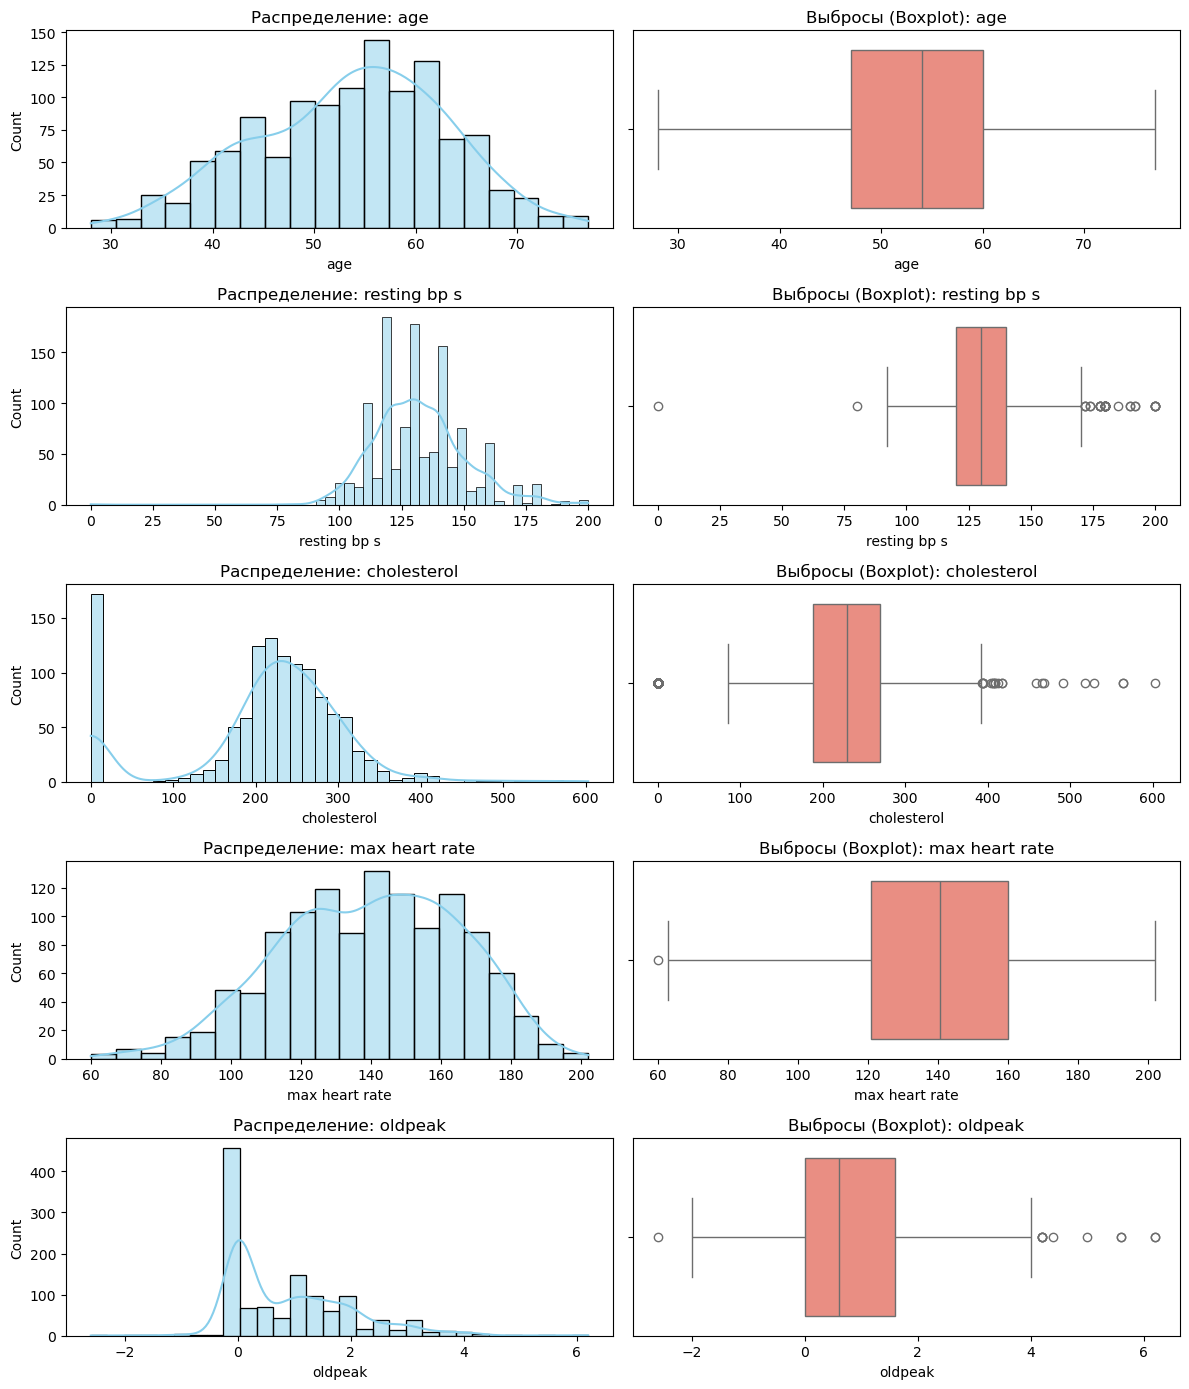

In [22]:
num_cols = ['age', 'resting bp s', 'cholesterol', 'max heart rate', 'oldpeak']

print("Статистическое описание числовых признаков:")
display(df[num_cols].describe().T)

fig, axes = plt.subplots(len(num_cols), 2, figsize=(12, 14))

for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[i, 0], color='skyblue')
    axes[i, 0].set_title(f'Распределение: {col}')
 
    sns.boxplot(x=df[col], ax=axes[i, 1], color='salmon')
    axes[i, 1].set_title(f'Выбросы (Boxplot): {col}')

plt.tight_layout()
plt.show()

/tmp/ipykernel_77242/4017798491.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, ax=axes[i], palette='Set2')
/tmp/ipykernel_77242/4017798491.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, ax=axes[i], palette='Set2')
/tmp/ipykernel_77242/4017798491.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, ax=axes[i], palette='Set2')
/tmp/ipykernel_77242/4017798491.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x`

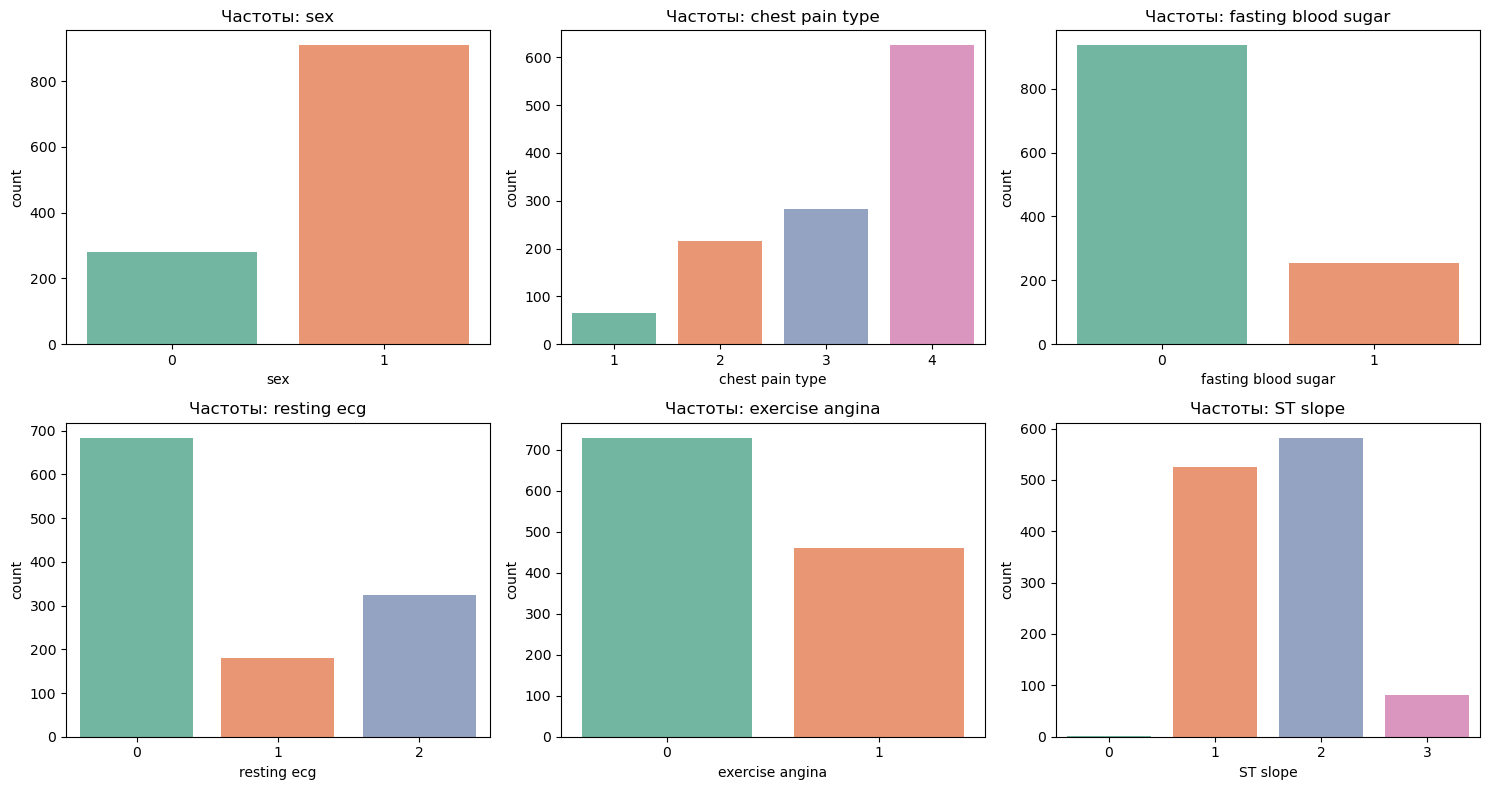

=== Распределение sex (%) ===
sex
1    76.39
0    23.61
Name: proportion, dtype: float64

=== Распределение chest pain type (%) ===
chest pain type
4    52.52
3    23.78
2    18.15
1     5.55
Name: proportion, dtype: float64

=== Распределение fasting blood sugar (%) ===
fasting blood sugar
0    78.66
1    21.34
Name: proportion, dtype: float64

=== Распределение resting ecg (%) ===
resting ecg
0    57.48
2    27.31
1    15.21
Name: proportion, dtype: float64

=== Распределение exercise angina (%) ===
exercise angina
0    61.26
1    38.74
Name: proportion, dtype: float64

=== Распределение ST slope (%) ===
ST slope
2    48.91
1    44.20
3     6.81
0     0.08
Name: proportion, dtype: float64



In [23]:
cat_cols = ['sex', 'chest pain type', 'fasting blood sugar', 'resting ecg', 'exercise angina', 'ST slope']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, ax=axes[i], palette='Set2')
    axes[i].set_title(f'Частоты: {col}')

plt.tight_layout()
plt.show()

for col in cat_cols:
    print(f"=== Распределение {col} (%) ===")
    print((df[col].value_counts(normalize=True) * 100).round(2))
    print()

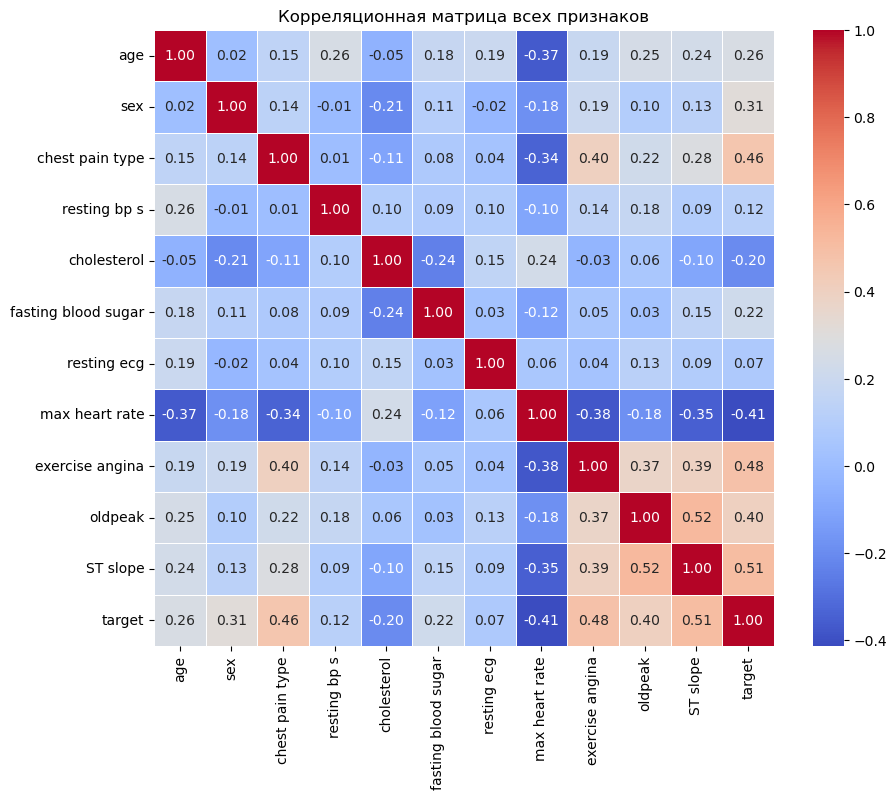

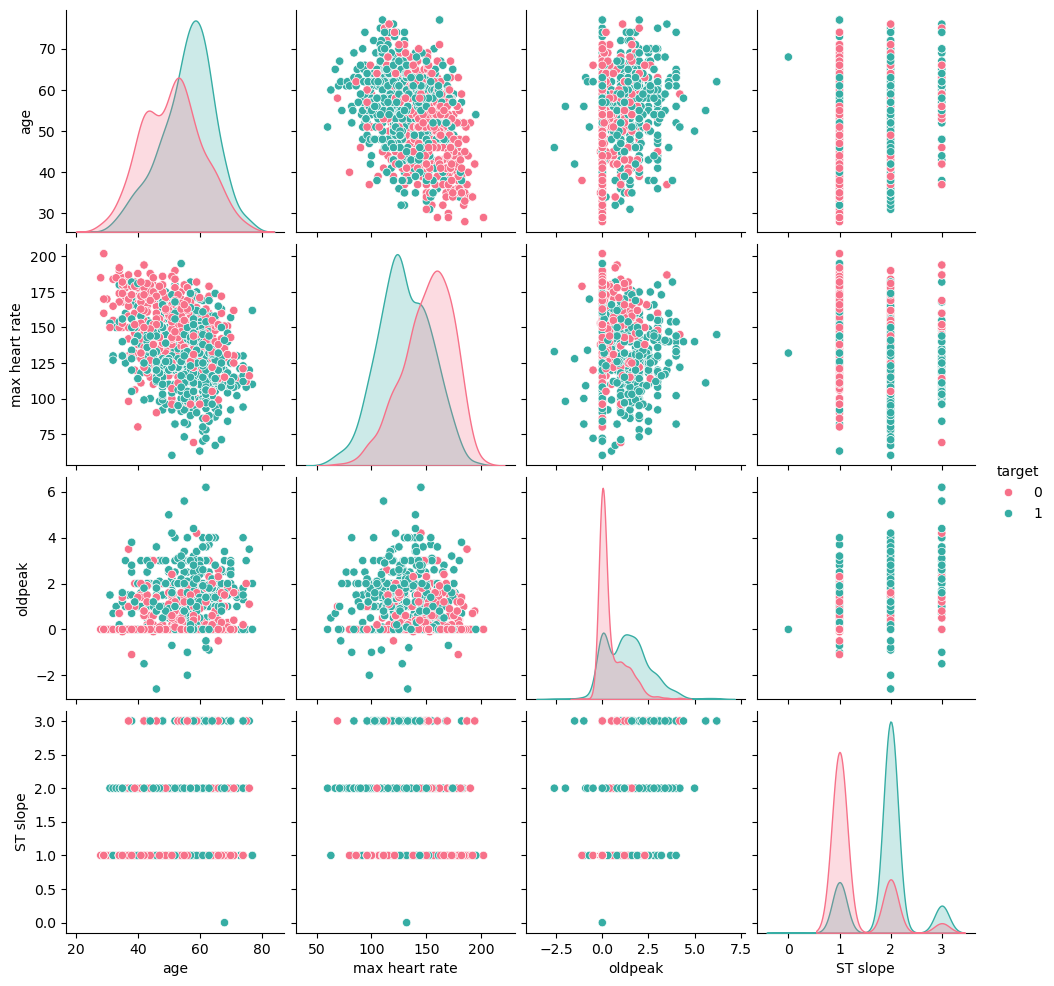

In [24]:
# Корреляционная матрица
plt.figure(figsize=(10, 8))
corr = df.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Корреляционная матрица всех признаков')
plt.show()

# Матрица рассеяния для наиболее скоррелированных с target признаков
top_corr_cols = ['age', 'max heart rate', 'oldpeak', 'ST slope', 'target']
sns.pairplot(df[top_corr_cols], hue='target', palette='husl')
plt.show()

/tmp/ipykernel_77242/3689439399.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='target', palette='viridis')


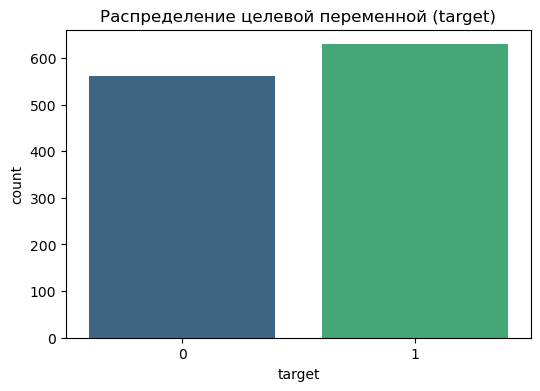

Соотношение классов target (%):
target
1    52.86
0    47.14
Name: proportion, dtype: float64


In [25]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='target', palette='viridis')
plt.title('Распределение целевой переменной (target)')
plt.show()

print("Соотношение классов target (%):")
print((df['target'].value_counts(normalize=True) * 100).round(2))

### Отчёт по результатам EDA (Уровень B)

1. **Пропуски в данных:** В датасете отсутствуют явные пропущенные значения (все 1190 строк полностью заполнены).
2. **Аномальные нулевые значения:** В признаках `cholesterol` и `resting bp s` обнаружены значения равные `0`, что биологически и физиологически невозможно. На следующем занятии их следует заменить на медианные значения по соответствующей возрастной и половой группе.
3. **Выбросы:** В непрерывных признаках `oldpeak`, `cholesterol` и `resting bp s` зафиксированы выбросы (по методу $IQR$). Их необходимо обработать клиппингом (винсоризацией) или нормализовать.
4. **Корреляции:** Наблюдается умеренная отрицательная корреляция между `age` и `max heart rate` ($r \approx -0.38$), а также сильная связь между `oldpeak` и `ST slope` с целевой переменной `target`. Кретической мультиколлинеарности ($\vert{}r\vert{} > 0.85$) нет.
5. **Дисбаланс классов:** Классы целевой переменной `target` распределены практически поровну (примерно 53% к 47%), сильный дисбаланс отсутствует, применять методы оверсэмплинга (SMOTE) не требуется.
6. **Подготовка к моделированию:** Категориальные признаки (`chest pain type`, `ST slope`, `resting ecg`) закодированы числами, поэтому на этапе предобработки их нужно перевести через `One-Hot Encoding`, а числовые шкалы привезти к единому масштабу с помощью `StandardScaler`.